**Practical No. 2**

---


Delivery Route Finder using BFS, DFS and A* Search Algorithms

**Name:** Tejas Narayan Mahamuni

**PRN:** 202401040036

**Roll No.** 7

**Github Link:** https://github.com/tejas-mahamuni/machine-learning.git



**Aim**

To design and implement a delivery route finder using graph-based Artificial Intelligence search algorithms such as Breadth First Search (BFS), Depth First Search (DFS), A*, Hill Climbing, Genetic, CSP Search to find routes from a warehouse in London to different delivery cities in England.

**Objective**

1. To represent the road network of England as a weighted graph.
2. To represent cities as nodes and roads as weighted edges.
3. To implement Breadth First Search (BFS).
4. To implement Depth First Search (DFS).
5. To implement A* Search using a heuristic function.
6. To calculate the total distance of a generated route.
8. To compare the routes generated by BFS, DFS and A*.
9. To implement Hill climbing and Genetic Local algorithm
10. To implement CSP by adding contraint for values and domains

**Graph Representation**

The delivery network is represented as a weighted undirected graph.

- Each city represents a node.
- Each road between two cities represents an edge.
- The weight of an edge represents the road distance in kilometres.
- London is considered the warehouse and starting point.
- Each delivery is associated with a destination city.
- Customer distances represent the additional distance required for completing deliveries within a city.

The graph contains the following major cities:

London, Birmingham, Bristol, Cambridge, Oxford, Nottingham,
Manchester, Sheffield, Leeds, Liverpool, Newcastle and Plymouth.

**Graph**

---

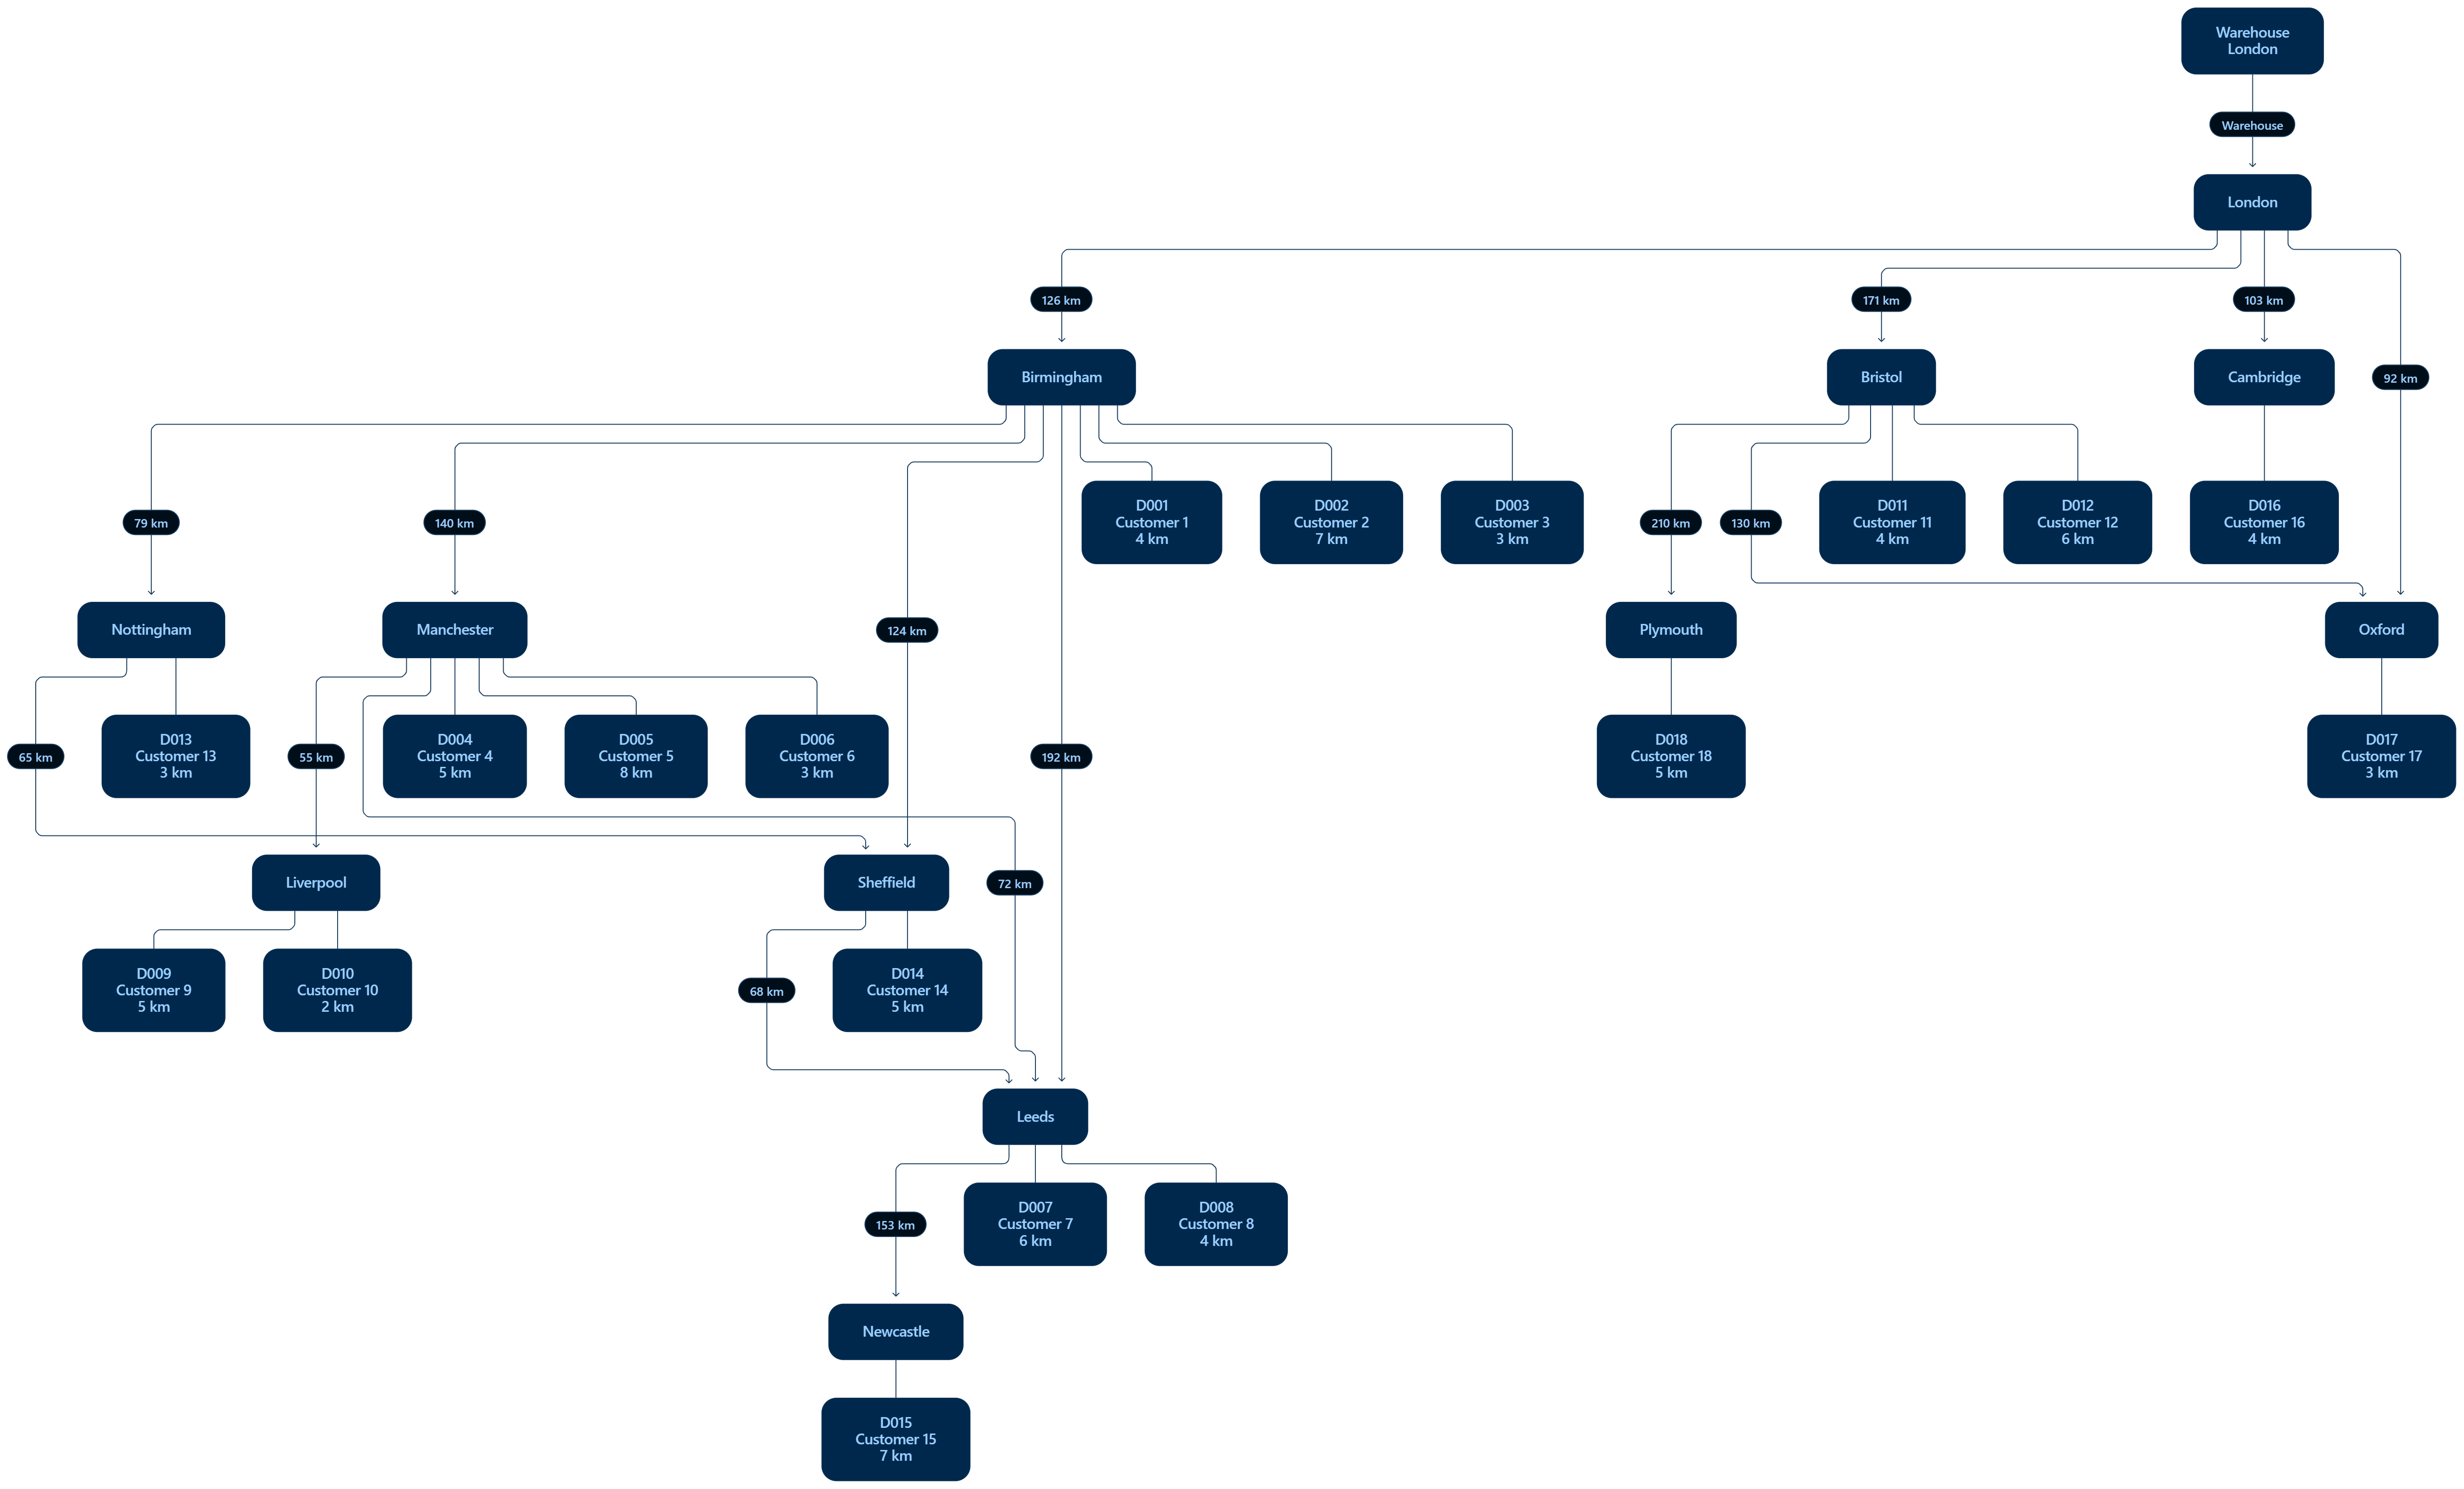

In [1]:
warehouse = "London"

graph = {
    "London": {
        "Birmingham": 126,
        "Bristol": 171,
        "Cambridge": 103,
        "Oxford": 92
    },

    "Birmingham": {
        "London": 126,
        "Nottingham": 79,
        "Manchester": 140,
        "Sheffield": 124,
        "Leeds": 192
    },

    "Bristol": {
        "London": 171,
        "Plymouth": 210,
        "Oxford": 130
    },

    "Cambridge": {
        "London": 103,
        "Oxford": 130
    },

    "Oxford": {
        "London": 92,
        "Bristol": 130,
        "Cambridge": 130
    },

    "Plymouth": {
        "Bristol": 210
    },

    "Nottingham": {
        "Birmingham": 79,
        "Sheffield": 65
    },

    "Manchester": {
        "Birmingham": 140,
        "Liverpool": 55,
        "Leeds": 72
    },

    "Liverpool": {
        "Manchester": 55
    },

    "Sheffield": {
        "Birmingham": 124,
        "Nottingham": 65,
        "Leeds": 67
    },

    "Leeds": {
        "Birmingham": 192,
        "Manchester": 72,
        "Sheffield": 67,
        "Newcastle": 153
    },

    "Newcastle": {
        "Leeds": 153
    }
}

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import math
import heapq
import random

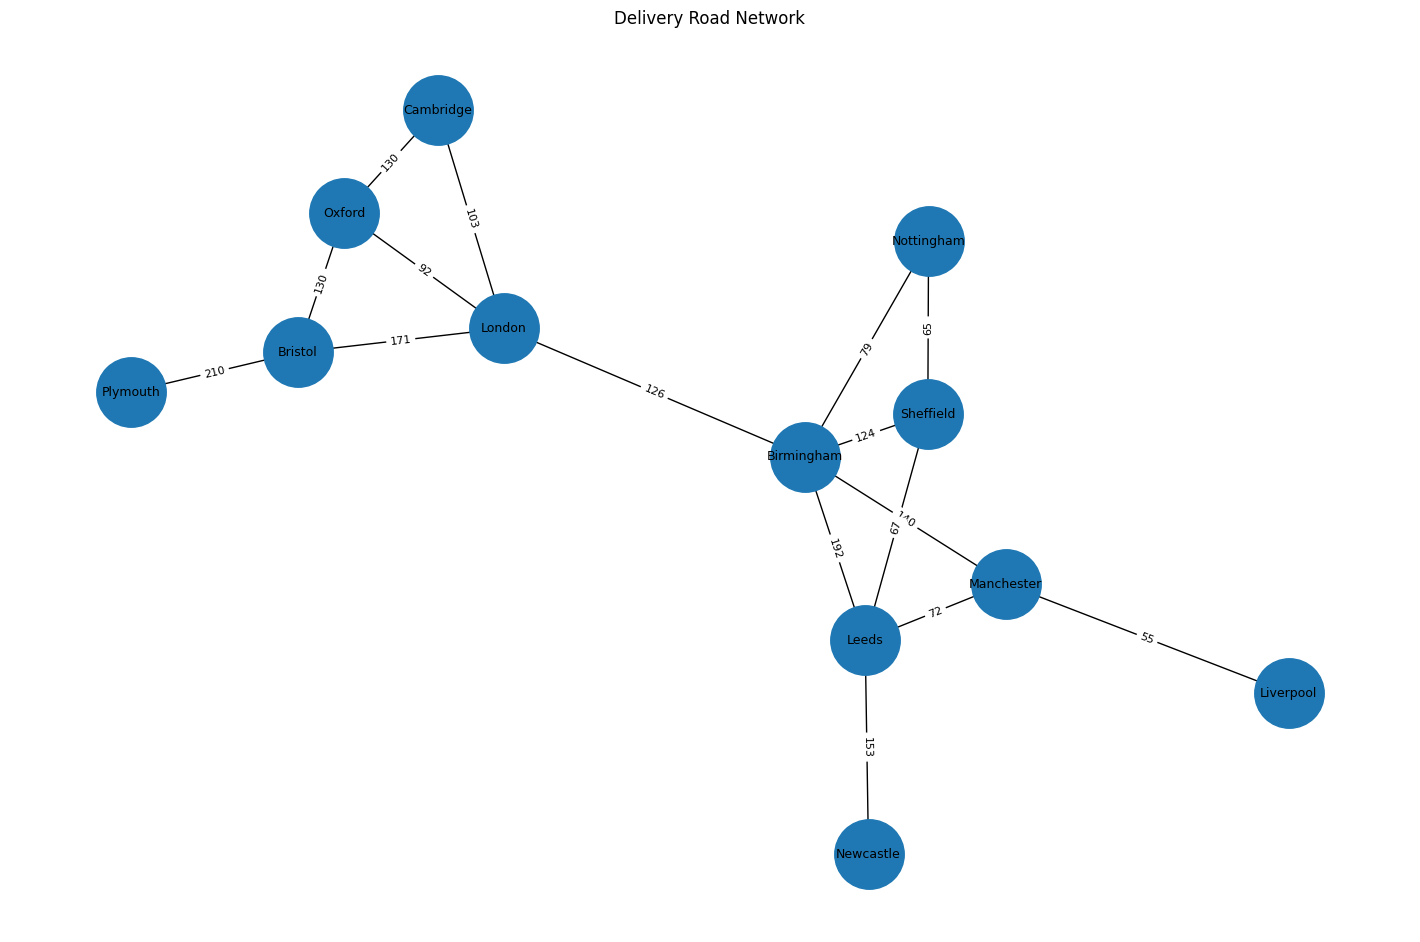

In [3]:
G = nx.Graph()

for city in graph:
    for neighbour, distance in graph[city].items():
        G.add_edge(city, neighbour, weight=distance)

plt.figure(figsize=(14, 9))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    font_size=9
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title("Delivery Road Network")
plt.show()

**Deliveries and Co-ordinates**

In [4]:
deliveries = {

    "D001": {
        "city": "Birmingham",
        "customer": "Customer 1",
        "distance": 4,
    },

    "D002": {
        "city": "Birmingham",
        "customer": "Customer 2",
        "distance": 7,
    },

    "D003": {
        "city": "Birmingham",
        "customer": "Customer 3",
        "distance": 3,
    },

    "D004": {
        "city": "Manchester",
        "customer": "Customer 4",
        "distance": 5,
    },

    "D005": {
        "city": "Manchester",
        "customer": "Customer 5",
        "distance": 8,
    },

    "D006": {
        "city": "Manchester",
        "customer": "Customer 6",
        "distance": 3,
    },

    "D007": {
        "city": "Leeds",
        "customer": "Customer 7",
        "distance": 6,
    },

    "D008": {
        "city": "Leeds",
        "customer": "Customer 8",
        "distance": 4,
    },

    "D009": {
        "city": "Liverpool",
        "customer": "Customer 9",
        "distance": 5,
    },

    "D010": {
        "city": "Liverpool",
        "customer": "Customer 10",
        "distance": 2,
    },

    "D011": {
        "city": "Bristol",
        "customer": "Customer 11",
        "distance": 4,
    },

    "D012": {
        "city": "Bristol",
        "customer": "Customer 12",
        "distance": 6,
    },

    "D013": {
        "city": "Nottingham",
        "customer": "Customer 13",
        "distance": 3,
    },

    "D014": {
        "city": "Sheffield",
        "customer": "Customer 14",
        "distance": 5,
    },

    "D015": {
        "city": "Newcastle",
        "customer": "Customer 15",
        "distance": 7,
    },

    "D016": {
        "city": "Cambridge",
        "customer": "Customer 16",
        "distance": 4,
    },

    "D017": {
        "city": "Oxford",
        "customer": "Customer 17",
        "distance": 3,
    },

    "D018": {
        "city": "Plymouth",
        "customer": "Customer 18",
        "distance": 4,
    }
}

coordinates = {

    "London": (51.5074, -0.1278),
    "Birmingham": (52.4862, -1.8904),
    "Bristol": (51.4545, -2.5879),
    "Nottingham": (52.9548, -1.1581),
    "Sheffield": (53.3811, -1.4701),
    "Manchester": (53.4808, -2.2426),
    "Liverpool": (53.4084, -2.9916),
    "Leeds": (53.8008, -1.5491),
    "Newcastle": (54.9783, -1.6178),
    "Plymouth": (50.3755, -4.1427),
    "Cambridge": (52.2053, 0.1218),
    "Oxford": (51.7520, -1.2577)
}

## Helper Functions

The following functions retrieve delivery information and calculate customer-level delivery distances.

In [5]:
def get_delivery_city (delivery_id):
    delivery = deliveries[delivery_id]
    city = delivery['city']

    return city

def get_city_deliveries(city):
    delivery_list = []

    for i in deliveries:
        delivery = deliveries[i]
        c = delivery['city']

        if c == city:
            delivery_list.append(i)

    return delivery_list

def calculate_delivery_distance(delivery_id):
    delivery = deliveries[delivery_id]
    distance = delivery['distance']

    return distance


def heuristic (city, goal):
    lat1, lon1 = coordinates[city]
    lat2, lon2 = coordinates[goal]

    return ((lat2 - lat1) ** 2 + (lon2- lon1) ** 2 ) ** 0.5

def haversine_heuristic (city, goal):
    lat1, lon1 = coordinates[city]
    lat2, lon2 = coordinates[goal]

    lat1 = math.radians(lat1)
    lat2 = math.radians(lat2)
    lon1 = math.radians(lon1)
    lon2 = math.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2

    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

    radius = 6371

    return radius * c

print("Delivery D001 destination:", get_delivery_city("D001"))

print("\nDeliveries in Birmingham:")
print(get_city_deliveries("Birmingham"))

print("\nCustomer distance for D001:")
print(calculate_delivery_distance("D001"), "km")

print("\nEuclidean heuristic:")
print("London -> Manchester:",
      round(heuristic("London", "Manchester"), 4))

print("\nHaversine heuristic:")
print("London -> Manchester:",
      round(haversine_heuristic("London", "Manchester"), 2), "km")


Delivery D001 destination: Birmingham

Deliveries in Birmingham:
['D001', 'D002', 'D003']

Customer distance for D001:
4 km

Euclidean heuristic:
London -> Manchester: 2.8925

Haversine heuristic:
London -> Manchester: 261.98 km


**Breadth First Search (BFS)**

BFS explores the graph level by level using a queue. It is useful for finding a path with the minimum number of edges in an unweighted graph. Since our road network has different edge weights, BFS is included mainly for algorithm comparison and demonstration.

In [6]:
def breadth_first_search (start, goal):
    queue = [start]
    visited = [start]

    parent = {start: None}

    while queue:
        current = queue.pop(0)

        if current == goal:
            break

        for i in graph[current]:
            if i not in visited:
                visited.append(i)
                parent[i] = current

                queue.append(i)

    if goal not in visited:
        return None

    route = []
    current = goal

    while current is not None:
        route.append(current)
        current = parent[current]

    route.reverse()

    return route

bfs_route = breadth_first_search("London", "Leeds")

print("BFS Route:")
print(" -> ".join(bfs_route))

BFS Route:
London -> Birmingham -> Leeds


**Depth First Search (DFS)**

DFS explores one branch deeply before backtracking. It uses a stack and is useful for graph exploration and finding a reachable path. However, it does not guarantee the minimum-distance route in a weighted graph.

In [7]:
def depth_first_search (start, goal):
    stack = [start]
    visited = {start}
    parent = {start: None}

    while stack:
        current = stack.pop()

        if (current == goal):
            break

        for i in graph[current]:

            if i not in visited:
                visited.add(i)
                parent[i] = current

                stack.append(i)

    if goal not in visited:
        return None

    route = []
    current = goal

    while current is not None:
        route.append(current)
        current = parent[current]

    route.reverse()

    return route


dfs_route = depth_first_search("London", "Leeds")

print("DFS Route:")
print(" -> ".join(dfs_route))

DFS Route:
London -> Birmingham -> Leeds


**A\* Search**

A* is an informed search algorithm that considers both:

- g(n): actual cost from the starting city to the current city
- h(n): estimated cost from the current city to the goal

The evaluation function is:

f(n) = g(n) + h(n)

The city with the lowest estimated total cost is selected for further exploration.

In [8]:
def a_star (start, goal):
    priority_queue = [(heuristic(start, goal), start)]

    visited = set()
    parent = {start: None}
    g_cost = {start: 0}

    while priority_queue:
        current_f, current = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)

        if current == goal:
            break

        for i in graph[current]:
            new_g_cost = g_cost[current] + graph[current][i]

            if i not in g_cost or new_g_cost < g_cost[i]:
                g_cost[i] = new_g_cost
                parent[i] = current

                h_cost = heuristic(i, goal)
                f_cost = new_g_cost + h_cost

                heapq.heappush(priority_queue, (f_cost, i))

    if goal not in visited:
        return None

    route = []
    current = goal

    while current is not None:
        route.append(current)
        current = parent[current]

    route.reverse()

    return route


astar_route = a_star("London", "Leeds")

print("A* Route:")
print(" -> ".join(astar_route))

A* Route:
London -> Birmingham -> Sheffield -> Leeds


In [9]:
def find_delivery_route(delivery_id, algorithm):
    city = get_delivery_city(delivery_id)

    if algorithm == "BFS":
        route = breadth_first_search(warehouse, city)

    elif algorithm == "DFS":
        route = depth_first_search(warehouse, city)

    elif algorithm == "A*":
        route = a_star(warehouse, city)

    else:
        return None

    return route

In [10]:
# Route Delivery Distance Calculation

def calculate_route_distance(route):
    total_distance = 0

    for i in range(len(route) - 1):
        current = route[i]
        next_city = route[i + 1]

        total_distance += graph[current][next_city]

    return total_distance

print("BFS distance:", calculate_route_distance(bfs_route), "km")
print("DFS distance:", calculate_route_distance(dfs_route), "km")
print("A* distance:", calculate_route_distance(astar_route), "km")

BFS distance: 318 km
DFS distance: 318 km
A* distance: 317 km


In [11]:
def calculate_delivery_route_distance(delivery_id, route):
    road_distance = calculate_route_distance(route)

    customer_distance = calculate_delivery_distance(delivery_id)

    return road_distance + customer_distance

print("BFS distance:", calculate_delivery_route_distance("D008", bfs_route), "km")
print("DFS distance:", calculate_delivery_route_distance("D008", dfs_route), "km")
print("A* distance:", calculate_delivery_route_distance("D008", astar_route), "km")

BFS distance: 322 km
DFS distance: 322 km
A* distance: 321 km


In [12]:
def display_route(delivery_id, algorithm):
    route = find_delivery_route(delivery_id, algorithm)

    if route is None:
        print("No route found.")
        return

    delivery = deliveries[delivery_id]

    road_distance = calculate_route_distance(route)
    total_distance = calculate_delivery_route_distance(delivery_id, route)

    print("\nDelivery Route -------------\n")

    print("Delivery ID:", delivery_id)
    print("Customer:", delivery["customer"])
    print("Destination:", delivery["city"])
    print("Algorithm:", algorithm)

    print("Route:", " -> ".join(route))

    print("Total Distance:", total_distance, "km\n")

    print("------------------------------\n")

display_route("D008", "BFS")
display_route("D008", "DFS")
display_route("D008", "A*")


Delivery Route -------------

Delivery ID: D008
Customer: Customer 8
Destination: Leeds
Algorithm: BFS
Route: London -> Birmingham -> Leeds
Total Distance: 322 km

------------------------------


Delivery Route -------------

Delivery ID: D008
Customer: Customer 8
Destination: Leeds
Algorithm: DFS
Route: London -> Birmingham -> Leeds
Total Distance: 322 km

------------------------------


Delivery Route -------------

Delivery ID: D008
Customer: Customer 8
Destination: Leeds
Algorithm: A*
Route: London -> Birmingham -> Sheffield -> Leeds
Total Distance: 321 km

------------------------------



**Comparison of BFS, DFS and A\***

The following function compares the routes generated by the three algorithms for the same delivery destination.

In [13]:
def compare_algorithms(delivery_id):
    city = get_delivery_city(delivery_id)

    bfs_route = breadth_first_search(warehouse, city)
    dfs_route = depth_first_search(warehouse, city)
    astar_route = a_star(warehouse, city)

    print("\n----------------------------------")
    print("Algorithm Comparison")
    print("----------------------------------\n")

    print("Delivery:", delivery_id)
    print("Customer:", deliveries[delivery_id]["customer"])
    print("Destination:", city)

    print("\nBFS")
    print("Route:", " -> ".join(bfs_route))
    print("Road Distance:", calculate_route_distance(bfs_route), "km")

    print("\nDFS")
    print("Route:", " -> ".join(dfs_route))
    print("Road Distance:", calculate_route_distance(dfs_route), "km")

    print("\nA*")
    print("Route:", " -> ".join(astar_route))
    print("Road Distance:", calculate_route_distance(astar_route), "km")

    print("----------------------------------\n")

compare_algorithms("D007")


----------------------------------
Algorithm Comparison
----------------------------------

Delivery: D007
Customer: Customer 7
Destination: Leeds

BFS
Route: London -> Birmingham -> Leeds
Road Distance: 318 km

DFS
Route: London -> Birmingham -> Leeds
Road Distance: 318 km

A*
Route: London -> Birmingham -> Sheffield -> Leeds
Road Distance: 317 km
----------------------------------



**Hill Climbing Algorithm**

In [14]:
delivery_graph = {

    "Birmingham": {
        "D001": {
            "D002": 5,
            "D003": 3
        },

        "D002": {
            "D001": 5,
            "D003": 6
        },

        "D003": {
            "D001": 3,
            "D002": 6
        }
    },


    "Manchester": {
        "D004": {
            "D005": 9,
            "D006": 4
        },

        "D005": {
            "D004": 6,
            "D006": 7
        },

        "D006": {
            "D004": 4,
            "D005": 7
        }
    },


    "Leeds": {
        "D007": {
            "D008": 5
        },

        "D008": {
            "D007": 5
        }
    },


    "Liverpool": {
        "D009": {
            "D010": 4
        },

        "D010": {
            "D009": 4
        }
    },


    "Bristol": {
        "D011": {
            "D012": 5
        },

        "D012": {
            "D011": 5
        }
    },


    "Nottingham": {
        "D013": {
        }
    },


    "Sheffield": {
        "D014": {
        }
    },


    "Newcastle": {
        "D015": {
        }
    },


    "Cambridge": {
        "D016": {
        }
    },


    "Oxford": {
        "D017": {
        }
    },


    "Plymouth": {
        "D018": {
        }
    }
}

In [15]:
def get_delivery_distance(delivery1, delivery2):

    city = deliveries[delivery1]["city"]

    return delivery_graph[city][delivery1][delivery2]


In [16]:
def calculate_delivery_path_distance(city, route, return_to_city=True):

    if not route:
        return 0

    total_distance = 0
    first_delivery = route[0]
    total_distance += deliveries[first_delivery]["distance"]

    for i in range(len(route) - 1):

        current = route[i]
        next_delivery = route[i + 1]

        total_distance += get_delivery_distance(
            current,
            next_delivery
        )

    if return_to_city:

        last_delivery = route[-1]
        total_distance += deliveries[last_delivery]["distance"]

    return total_distance

In [17]:
def hill_climbing_delivery(city):

    current_route = get_city_deliveries(city)
    current_distance = calculate_delivery_path_distance(city, current_route)

    while True:

        best_route = current_route
        best_distance = current_distance

        for i in range(len(current_route)):

            for j in range(i + 1, len(current_route)):

                new_route = current_route.copy()
                new_route[i], new_route[j] = (new_route[j], new_route[i])

                new_distance = calculate_delivery_path_distance(city, new_route)

                if new_distance < best_distance:
                    best_route = new_route
                    best_distance = new_distance

        if best_distance >= current_distance:
            break

        current_route = best_route
        current_distance = best_distance

    return current_route, current_distance

In [18]:
hill_route, hill_distance = hill_climbing_delivery("Manchester")

print("Hill Climbing")
print("------------------------------")
print("City:", "Birmingham")
print("Delivery Order:", " -> ".join(hill_route))
print("Total Distance:", hill_distance, "km")

Hill Climbing
------------------------------
City: Birmingham
Delivery Order: D005 -> D004 -> D006
Total Distance: 21 km


**Genetic Algorithm**

In [19]:
def create_population(city, population_size=10):

    deliveries_in_city = get_city_deliveries(city)

    population = []

    for i in range(population_size):

        route = deliveries_in_city.copy()
        random.shuffle(route)

        population.append(route)

    return population

In [20]:
def calculate_fitness(city, route):

    distance = calculate_delivery_path_distance(city, route)

    if distance == 0:
        return 0

    return 1 / distance

In [21]:
def select_parents(city, population):

    population.sort(
        key=lambda route:
        calculate_delivery_path_distance(
            city,
            route
        )
    )

    return population[:len(population) // 2]

In [22]:
def crossover(parent1, parent2):

    start = random.randint(0, len(parent1) - 2)
    end = random.randint(start + 1, len(parent1) - 1)

    child = [None] * len(parent1)
    child[start:end + 1] = parent1[start:end + 1]

    remaining = []

    for delivery in parent2:
        if delivery not in child:
            remaining.append(delivery)

    index = 0

    for i in range(len(child)):
        if child[i] is None:
            child[i] = remaining[index]

            index += 1

    return child

In [23]:
def mutate(route, mutation_rate=0.1):

    route = route.copy()

    if random.random() < mutation_rate:

        i, j = random.sample(range(len(route)), 2)

        route[i], route[j] = (
            route[j],
            route[i]
        )

    return route

In [24]:
def genetic_algorithm(city, population_size=10, generations=50, mutation_rate=0.1):

    population = create_population(city, population_size)

    for generation in range(generations):

        parents = select_parents(city, population)
        new_population = parents.copy()

        while len(new_population) < population_size:

            parent1 = random.choice(parents)
            parent2 = random.choice(parents)

            child = crossover(parent1, parent2)
            child = mutate(child, mutation_rate)

            new_population.append(child)

        population = new_population

    best_route = min(population, key=lambda route: calculate_delivery_path_distance(city, route))
    best_distance = calculate_delivery_path_distance(city, best_route)

    return best_route, best_distance

In [25]:
def display_genetic_algorithm(city):

    route, distance = genetic_algorithm(
        city,
        population_size=10,
        generations=50,
        mutation_rate=0.1
    )

    print("\n----------------------------------")
    print("Genetic Algorithm Delivery Route")
    print("----------------------------------")

    print("City:", city)

    print("Deliveries:")

    for delivery_id in route:

        delivery = deliveries[delivery_id]

        print(
            delivery_id,
            "-",
            delivery["customer"],
            "-",
            delivery["distance"],
            "km"
        )

    print("\nOptimized Order:")
    print(" -> ".join(route))

    print("Total Distance:", distance, "km")

    print("----------------------------------")

In [26]:
display_genetic_algorithm("Manchester")


----------------------------------
Genetic Algorithm Delivery Route
----------------------------------
City: Manchester
Deliveries:
D006 - Customer 6 - 3 km
D005 - Customer 5 - 8 km
D004 - Customer 4 - 5 km

Optimized Order:
D006 -> D005 -> D004
Total Distance: 21 km
----------------------------------


**Contraint Satisfaction Problem**

In [27]:
def get_delivery_cities():
    cities = set()
    for delivery_id in deliveries:
        cities.add(deliveries[delivery_id]['city'])
    return sorted(list(cities))

delivery_cities = get_delivery_cities()

print(delivery_cities)

['Birmingham', 'Bristol', 'Cambridge', 'Leeds', 'Liverpool', 'Manchester', 'Newcastle', 'Nottingham', 'Oxford', 'Plymouth', 'Sheffield']


In [28]:
variables = delivery_cities

domains = {}

for city in variables:
    domains[city] = ["Van 1", "Van 2"]

In [29]:
def calculate_van_load(assignment, van):
    total = 0

    for city in assignment:
        if assignment[city] == van:
            total += len(get_city_deliveries(city))

    return total

In [30]:
def is_valid_csp(assignment, city, van):

    # Temporarily assign the city
    assignment[city] = van

    van1_load = calculate_van_load(
        assignment,
        "Van 1"
    )

    van2_load = calculate_van_load(
        assignment,
        "Van 2"
    )

    # Workload difference should not exceed 2
    if abs(van1_load - van2_load) > 3:
        del assignment[city]
        return False

    del assignment[city]

    return True

In [31]:
def backtracking_csp(assignment):

    # All cities assigned
    if len(assignment) == len(variables):
        return assignment.copy()

    # Select next unassigned city
    for city in variables:
        if city not in assignment:

            for van in domains[city]:

                if is_valid_csp(
                    assignment,
                    city,
                    van
                ):

                    assignment[city] = van

                    result = backtracking_csp(
                        assignment
                    )

                    if result is not None:
                        return result

                    del assignment[city]

            return None

In [32]:
csp_solution = backtracking_csp({})
print(csp_solution)

{'Birmingham': 'Van 1', 'Bristol': 'Van 2', 'Cambridge': 'Van 1', 'Leeds': 'Van 2', 'Liverpool': 'Van 1', 'Manchester': 'Van 2', 'Newcastle': 'Van 1', 'Nottingham': 'Van 1', 'Oxford': 'Van 1', 'Plymouth': 'Van 1', 'Sheffield': 'Van 2'}


In [33]:
def main():

    while True:

        print("\n--------------------------------------")
        print("       DELIVERY ROUTE FINDER")
        print("---------------------------------------\n")

        print("Warehouse:", warehouse)

        print("\n1. Find route for delivery")
        print("2. Compare BFS, DFS and A*")
        print("3. Show deliveries in a city")
        print("4. Show all deliveries")
        print("5. Exit")

        choice = input("\nEnter your choice: ")

        if choice == "1":

            delivery_id = input("Enter delivery ID: ").upper()

            if delivery_id not in deliveries:
                print("Invalid delivery ID.")
                continue

            print("\nSelect algorithm:")
            print("1. BFS")
            print("2. DFS")
            print("3. A*")

            algorithm_choice = input("Enter choice: ")

            if algorithm_choice == "1":
                algorithm = "BFS"

            elif algorithm_choice == "2":
                algorithm = "DFS"

            elif algorithm_choice == "3":
                algorithm = "A*"

            else:
                print("Invalid algorithm.")
                continue

            display_route(delivery_id, algorithm)

        elif choice == "2":

            delivery_id = input("Enter delivery ID: ").upper()

            if delivery_id not in deliveries:
                print("Invalid delivery ID.")
                continue

            compare_algorithms(delivery_id)

        elif choice == "3":

            city = input("Enter city: ")

            delivery_list = get_city_deliveries(city)

            if delivery_list:
                print("\nDeliveries in", city)

                for delivery_id in delivery_list:
                    delivery = deliveries[delivery_id]

                    print(
                        delivery_id,
                        "-",
                        delivery["customer"],
                        "-",
                        delivery["distance"],
                        "km"
                    )

            else:
                print("No deliveries found.")

        elif choice == "4":

            print("\nAll Deliveries")

            for delivery_id in deliveries:

                delivery = deliveries[delivery_id]

                print(
                    delivery_id,
                    "-",
                    delivery["customer"],
                    "-",
                    delivery["city"],
                    "-",
                    delivery["distance"],
                    "km"
                )

        elif choice == "5":

            print("Exiting Delivery Route Finder.")
            break

        else:

            print("Invalid choice. Please try again.")


In [34]:
# if __name__ == "__main__":
#     main()

**Conclusion**

The Delivery Route Finder was successfully implemented using graph-based Artificial Intelligence search algorithms. The road network was represented as a weighted graph where cities were nodes and road distances were edge weights.

BFS and DFS were implemented to demonstrate uninformed search techniques, while A* was implemented as an informed search algorithm using a geographical heuristic. The route distance calculation was used to compare the paths generated by different algorithms.

Local Search Algorithms such as Hill Climbing and genetic algorithm were implemented for finding best route for deliveries in a city.

Contraints Satisfaction Problem Algorithm to allocated city deliveries for 2 vans, such load between them should not be greater then 2.

The system was also extended to handle multiple deliveries within the same city, allowing the warehouse-to-city route to be calculated once while processing all customers in that city.

Thus, the practical demonstrates how AI search algorithms can be applied to a real-world delivery and route-finding problem.